# Prédiction de prix de airbnb

But : Prédire le logarithme du prix du airbnb à partir d'un ensemble d'informations brut sur le logement

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline


In [15]:
# Chargement du fichier csv
df = pd.read_csv("airbnb_train.csv")
df.head()

,id,log_price,property_type,room_type,amenities,accommodates,bathrooms,bed_type,cancellation_policy,cleaning_fee,...,last_review,latitude,longitude,name,neighbourhood,number_of_reviews,review_scores_rating,zipcode,bedrooms,beds
0,5708593,4.317488,House,Private room,"{TV,""Wireless Internet"",Kitchen,""Free parking ...",3,1.0,Real Bed,flexible,False,...,NaN,33.782712,-118.134410,Island style Spa Studio,Long Beach,0,NaN,90804,0.0,2.0
1,14483613,4.007333,House,Private room,"{""Wireless Internet"",""Air conditioning"",Kitche...",4,2.0,Real Bed,strict,False,...,2017-09-17,40.705468,-73.909439,"Beautiful and Simple Room W/2 Beds, 25 Mins to...",Ridgewood,38,86.0,11385,1.0,2.0
2,10412649,7.090077,Apartment,Entire home/apt,"{TV,""Wireless Internet"",""Air conditioning"",Kit...",6,2.0,Real Bed,flexible,False,...,NaN,38.917537,-77.031651,2br/2ba luxury condo perfect for infant / toddler,U Street Corridor,0,NaN,20009,2.0,2.0
3,17954362,3.555348,House,Private room,"{TV,""Cable TV"",Internet,""Wireless Internet"",""A...",1,1.0,Real Bed,flexible,True,...,2017-09-29,40.736001,-73.924248,Manhattan view from Queens. Lovely single room .,Sunnyside,19,96.0,11104,1.0,1.0
4,9969781,5.480639,House,Entire home/apt,"{TV,""Cable TV"",Internet,""Wireless Internet"",Ki...",4,1.0,Real Bed,moderate,True,...,2017-08-28,37.744896,-122.430665,Zen Captured Noe Valley House,Noe Valley,15,96.0,94131,2.0,2.0


## Section 1 : Présentation des données

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22234 entries, 0 to 22233
Data columns (total 28 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id                      22234 non-null  int64  
 1   log_price               22234 non-null  float64
 2   property_type           22234 non-null  object 
 3   room_type               22234 non-null  object 
 4   amenities               22234 non-null  object 
 5   accommodates            22234 non-null  int64  
 6   bathrooms               22183 non-null  float64
 7   bed_type                22234 non-null  object 
 8   cancellation_policy     22234 non-null  object 
 9   cleaning_fee            22234 non-null  bool   
 10  city                    22234 non-null  object 
 11  description             22234 non-null  object 
 12  first_review            17509 non-null  object 
 13  host_has_profile_pic    22178 non-null  object 
 14  host_identity_verified  22178 non-null

On voit que de nombreuses données ne sont pas au format numériques et donc difficilement exploitables en l'état avec les algos que l'on utilise.

In [5]:
df.columns

Index(['id', 'log_price', 'property_type', 'room_type', 'amenities',
       'accommodates', 'bathrooms', 'bed_type', 'cancellation_policy',
       'cleaning_fee', 'city', 'description', 'first_review',
       'host_has_profile_pic', 'host_identity_verified', 'host_response_rate',
       'host_since', 'instant_bookable', 'last_review', 'latitude',
       'longitude', 'name', 'neighbourhood', 'number_of_reviews',
       'review_scores_rating', 'zipcode', 'bedrooms', 'beds'],
      dtype='object')

In [6]:
print("\n=== Statistiques pour colonnes numériques ===")
df.describe()


=== Statistiques pour colonnes numériques ===


,id,log_price,accommodates,bathrooms,latitude,longitude,number_of_reviews,review_scores_rating,bedrooms,beds
count,2.223400e+04,22234.000000,22234.000000,22183.000000,22234.000000,22234.000000,22234.000000,17256.000000,22208.000000,22199.000000
mean,1.122269e+07,4.783481,3.155573,1.236037,38.462971,-92.269305,20.670774,94.069077,1.264769,1.711473
std,6.080480e+06,0.718758,2.143870,0.586246,3.071679,21.670081,37.183731,7.782235,0.852819,1.254903
min,3.362000e+03,2.302585,1.000000,0.000000,33.339002,-122.510940,0.000000,20.000000,0.000000,0.000000
25%,6.202924e+06,4.317488,2.000000,1.000000,34.136082,-118.340633,1.000000,92.000000,1.000000,1.000000
50%,1.217425e+07,4.700480,2.000000,1.000000,40.662632,-76.994944,6.000000,96.000000,1.000000,1.000000
75%,1.639502e+07,5.220356,4.000000,1.000000,40.746358,-73.954599,23.000000,100.000000,1.000000,2.000000
max,2.120450e+07,7.600402,16.000000,8.000000,42.390248,-70.989359,505.000000,100.000000,10.000000,18.000000


Les variables numériques sont sur des échelles très différentes (ex: `latitude` ~40, `bedrooms` ~1, `number_of_reviews` jusqu'à 505). Une standardisation sera appliquée avant les modèles sensibles aux échelles (régression linéaire, ACP).

In [7]:
print("\n=== Nombre de valeurs nulles ===")
df.isnull().sum()


=== Nombre de valeurs nulles ===


id                           0
log_price                    0
property_type                0
room_type                    0
amenities                    0
accommodates                 0
bathrooms                   51
bed_type                     0
cancellation_policy          0
cleaning_fee                 0
city                         0
description                  0
first_review              4725
host_has_profile_pic        56
host_identity_verified      56
host_response_rate        5475
host_since                  56
instant_bookable             0
last_review               4716
latitude                     0
longitude                    0
name                         0
neighbourhood             2086
number_of_reviews            0
review_scores_rating      4978
zipcode                    303
bedrooms                    26
beds                        35
dtype: int64

Certaines variables ont des valeurs manquantes :
- `bathrooms`, `bedrooms`, `beds` (<1%) → remplacement par la médiane
- `host_response_rate`, `review_scores_rating` (~22-25%) → remplacement par la médiane
- `first_review`, `last_review` (~21%) → les nulls signifient "jamais de review", 
  traités lors du feature engineering
- `neighbourhood` (9% + trop de valeurs uniques) → supprimée

## Section 2 : Distribution de la variable cible (log_price)

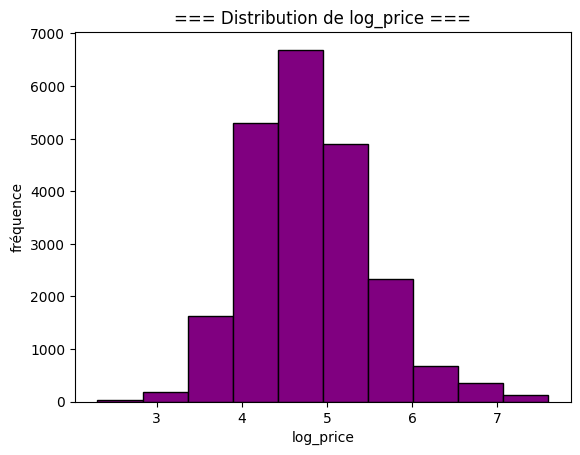

In [8]:
plt.title("=== Distribution de log_price ===")
plt.hist(df["log_price"],bins=10,color="purple",edgecolor="black")
plt.xlabel("log_price")
plt.ylabel("fréquence")
plt.show()

## Section 3 : Exploration des variables catégorielles et numériques

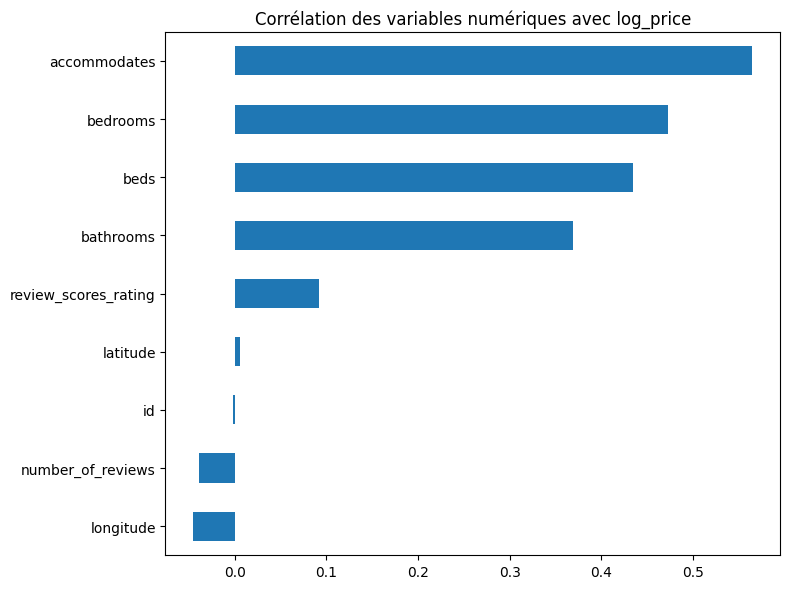

In [12]:
# Sélectionner uniquement les colonnes numériques
numeric_cols = df.select_dtypes(include=['number']).columns

corr = df[numeric_cols].corr()['log_price'].drop('log_price').sort_values()
corr.plot(kind='barh', figsize=(8, 6))
plt.title('Corrélation des variables numériques avec log_price')
plt.tight_layout()
plt.show()

## Observations
- Les variables de capacité (`accommodates`, `bedrooms`, `beds`, `bathrooms`) sont 
  fortement corrélées avec `log_price` : plus le logement est grand, plus il est cher.
- `latitude`/`longitude` ont une corrélation linéaire quasi nulle, mais on les conserve
  car des modèles non-linéaires (Random Forest) peuvent détecter des effets de zone.
- `id` est un identifiant sans valeur prédictive : on le supprime.

## L'idée
`accommodates`, `bedrooms`, `beds`, `bathrooms` sont toutes fortement corrélées entre elles et avec `log_price`. Un grand appartement a tendance à avoir beaucoup de chambres, beaucoup de lits, beaucoup de salles de bain... Ces 4 colonnes portent en grande partie la même information : "la taille du logement".
L'ACP va justement détecter ça et créer une nouvelle colonne, qu'on appellera composante principale, résumant ces 4 variables en 1 seule, tout en gardant le maximum d'information.

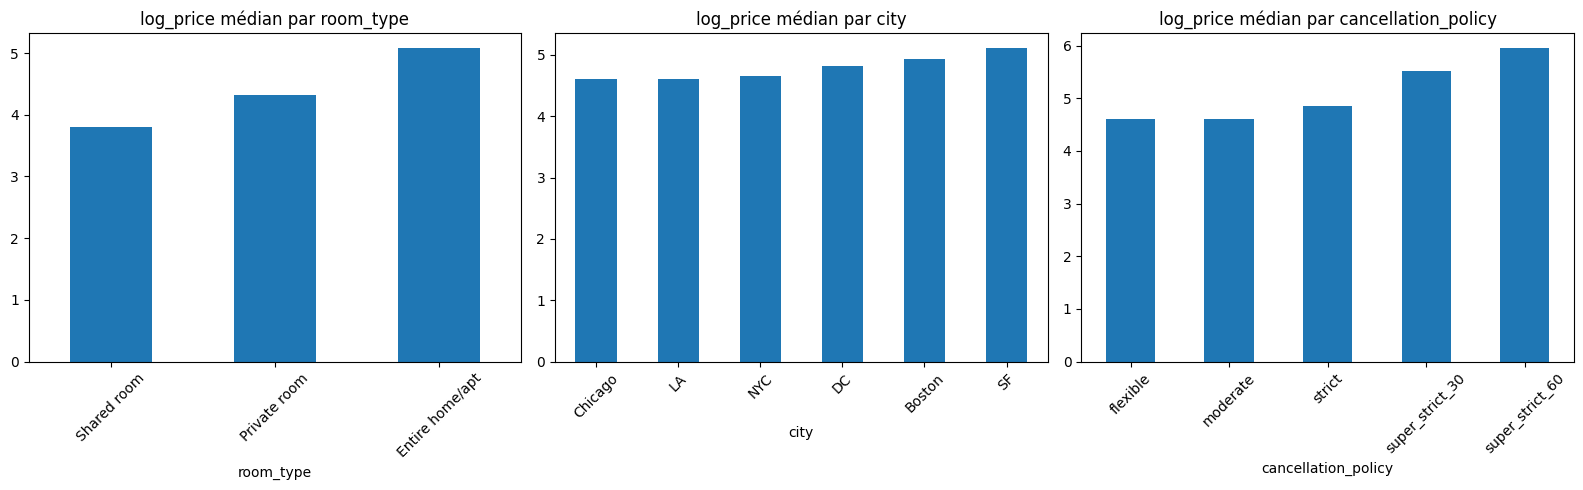

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, col in zip(axes, ['room_type', 'city', 'cancellation_policy']):
    df.groupby(col)['log_price'].median().sort_values().plot(kind='bar', ax=ax)
    ax.set_title(f'log_price médian par {col}')
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

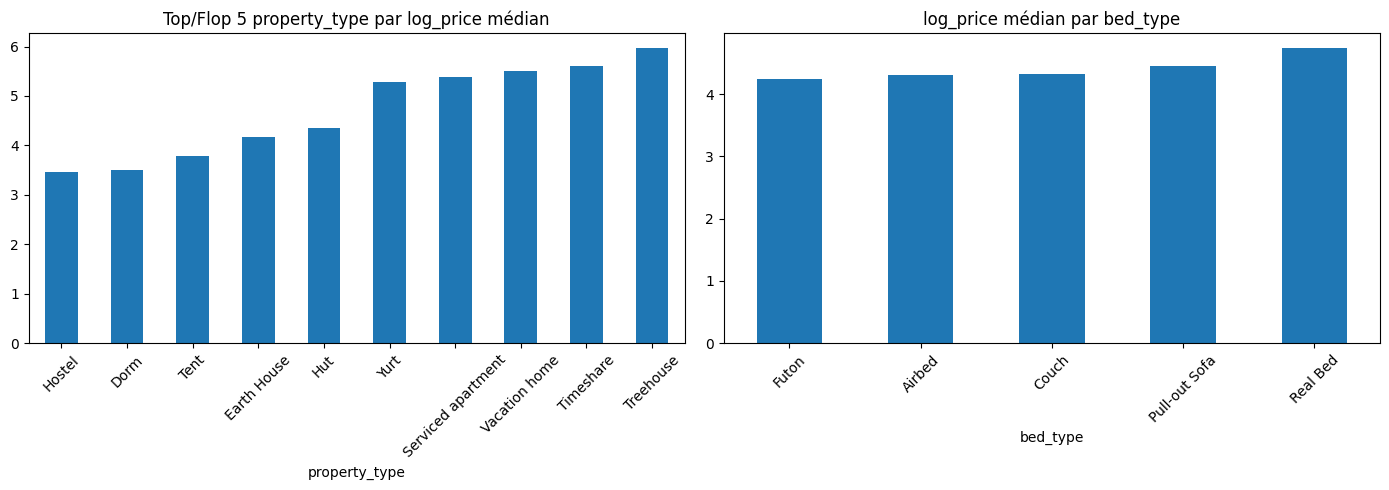

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# property_type : 5 premiers et 5 derniers uniquement car sinon c'est illisible
medians = df.groupby('property_type')['log_price'].median().sort_values()
pd.concat([medians.head(5), medians.tail(5)]).plot(kind='bar', ax=axes[0])
axes[0].set_title('Top/Flop 5 property_type par log_price médian')
axes[0].tick_params(axis='x', rotation=45)

# bed_type : tous 
df.groupby('bed_type')['log_price'].median().sort_values().plot(kind='bar', ax=axes[1])
axes[1].set_title('log_price médian par bed_type')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

## Observations

``property_type`` : Grande disparité de prix selon le type de bien. 
Les hébergements insolites (``Treehouse``, ``Timeshare``) sont les plus chers, 
tandis que les hébergements collectifs (``Hostel``, ``Dorm``) sont les moins chers. 
Cette variable sera donc à conservée par la suite.

``bed_type``: Faible disparité des prix (de 4.2 à 5.8). 
``Real Bed`` est légèrement plus cher. Variable conservée mais probablement peu influente.

## Conclusion de l'exploration

- Variables à encoder (texte → nombres) : ``room_type``, ``city``, 
``cancellation_policy``, ``property_type``, ``bed_type``

- Variables à transformer : ``amenities``, ``host_since``, ``first_review``, 
``last_review``, ``host_response_rate``, ``cleaning_fee``, ``host_has_profile_pic``,
``host_identity_verified``, ``instant_bookable``

- Variables à supprimer : ``id``, ``description``, ``name``, ``zipcode``, ``neighbourhood``



## Section 4 : Feature engineering

In [16]:
# Suppresion des colonnes inutiles 
df = df.drop(columns=['id', 'description', 'name', 'zipcode', 'neighbourhood'])
df.shape

(22234, 23)

In [17]:
# Remplissage des valeurs manquantes
# Numériques ==> médiane
for col in ['bathrooms', 'bedrooms', 'beds', 'review_scores_rating']:
    df[col] = df[col].fillna(df[col].median())

# host_response_rate : enlever le % puis médiane
df['host_response_rate'] = df['host_response_rate'].str.replace('%', '').astype(float)
df['host_response_rate'] = df['host_response_rate'].fillna(df['host_response_rate'].median())



In [ ]:
# Conversion des valeurs booléennes informelles
for col in ['host_has_profile_pic', 'host_identity_verified', 'instant_bookable']:
    df[col] = df[col].map({'t': 1, 'f': 0, True: 1, False: 0})

df.iloc[0:6,11:18]


,host_has_profile_pic,host_identity_verified,host_response_rate,host_since,instant_bookable,last_review,latitude
0,1.0,0.0,100.0,2015-12-12,1,NaN,33.782712
1,1.0,1.0,100.0,2016-11-04,1,2017-09-17,40.705468
2,1.0,0.0,100.0,2016-12-11,1,NaN,38.917537
3,1.0,1.0,100.0,2012-08-04,0,2017-09-29,40.736001
4,1.0,1.0,100.0,2013-07-25,0,2017-08-28,37.744896
5,1.0,1.0,100.0,2012-11-19,0,NaN,40.738580


In [ ]:
# Transformation des dates au format numériques
df['last_review'] = pd.to_datetime(df['last_review'], errors='coerce')
ref = df['last_review'].max() + pd.Timedelta(days=1) # date la plus récente du dataset + 1 jour

for col in ['host_since', 'first_review', 'last_review']:
    df[col] = pd.to_datetime(df[col], errors='coerce')
    df[col] = (ref - df[col]).dt.days.fillna(0) # nombre de jour d'activité

df[['host_since', 'first_review', 'last_review']].head()

,host_since,first_review,last_review
0,664.0,0.0,0.0
1,336.0,152.0,19.0
2,299.0,0.0,0.0
3,1889.0,364.0,7.0
4,1534.0,376.0,39.0


In [42]:
# Quels sont les équipements les plus fréquents ?
from collections import Counter

all_amenities = df['amenities'].str.strip('{}').str.replace('"', '').str.split(',')
counter = Counter([a.strip() for sublist in all_amenities for a in sublist])

#pd.Series(counter).info()
pd.Series(counter).sort_values(ascending=False).to_csv("Amenities.csv")

## Observation
Parmi les équipements les plus fréquents, certains sont liés à la législation (détecteur de fumée, extincteur...) et non au confort ou au standing du logement. On les exclut manuellement car ils ne sont pas significativement impactant sur le prix.
On retient les équipements de confort les plus fréquent en excluant : 
- Sécurité/législation : ``Smoke detector``, ``Carbon monoxide detector``, ``Fire extinguisher``, ``First aid kit`` (obligatoires dans beaucoup d'états)
- Accessibilité : ``Wide doorway``, ``Wheelchair accessible``, etc. (non liés au prix)
- Trop rares (<100 occurrences) : ``Beachfront``, ``Ski in/Ski out``, etc.
- Ambigus : "translation missing", "Other"

In [45]:
# Extraction des données dans amenities (= infrastructures)

amenities_to_extract = {
    'has_tv': 'TV',
    'has_wifi': 'Wireless Internet',
    'has_kitchen': 'Kitchen',
    'has_free_parking': 'Free parking on premises',
    'has_washer': 'Washer',
    'has_dryer': 'Dryer',
    'has_ac': 'Air conditioning',
    'has_heating': 'Heating',
    'has_family_friendly': 'Family/kid friendly',
    'has_laptop_workspace': 'Laptop friendly workspace',
    'has_cable_tv': 'Cable TV',
    'has_internet': 'Internet',
    'has_breakfast': 'Breakfast',
    'has_gym': 'Gym',
    'has_hot_tub': 'Hot tub',
    'has_pool': 'Pool',
    'has_pets_allowed': 'Pets allowed',
    'has_24h_checkin': '24-hour check-in',
    'has_self_checkin': 'Self Check-In',
}

for col_name, amenity in amenities_to_extract.items():
    df[col_name] = df['amenities'].str.contains(amenity, case=False).astype(int)

df['nb_amenities'] = df['amenities'].str.count(',') + 1
df = df.drop(columns=['amenities'])
df.head()

,log_price,property_type,room_type,accommodates,bathrooms,bed_type,cancellation_policy,cleaning_fee,city,first_review,...,has_laptop_workspace,has_cable_tv,has_internet,has_breakfast,has_gym,has_hot_tub,has_pool,has_pets_allowed,has_24h_checkin,has_self_checkin
0,4.317488,House,Private room,3,1.0,Real Bed,flexible,False,LA,0.0,...,0,0,1,0,0,0,0,1,0,0
1,4.007333,House,Private room,4,2.0,Real Bed,strict,False,NYC,152.0,...,0,0,1,0,0,0,0,0,1,1
2,7.090077,Apartment,Entire home/apt,6,2.0,Real Bed,flexible,False,DC,0.0,...,1,0,1,0,0,0,0,1,0,0
3,3.555348,House,Private room,1,1.0,Real Bed,flexible,True,NYC,364.0,...,1,1,1,1,0,0,0,0,0,1
4,5.480639,House,Entire home/apt,4,1.0,Real Bed,moderate,True,SF,376.0,...,1,1,1,1,0,0,0,0,1,1
